# Optimization vs. expressibility of the circuit

## Overview

In this tutorial, we use the variational quantum eigensolver (VQE) to compare energy and entanglement before and after optimization at different circuit depths.

The model considered here reads:
$$
H = \sum_{i=1}^{n}\sigma_{i}^{z}\sigma_{i+1}^{z}+\sum_{i=1}^{n}\sigma_{i}^{x},
$$
where $\sigma_{i}^{x,z}$ are Pauli matrices of the $i$-th qubit. We characterize the circuit-state entanglement using the second Rényi entropy:
$$
R_{A}^{2} = - \rm{log} (\rm{tr}_{A}\rho_{A}^{2}),
$$
where $\rho_{A}$ is the reduced density matrix of one half of the chain, obtained by tracing out the other half.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorcircuit as tc
import quspin

tc.set_backend("tensorflow")
tc.set_dtype("complex128")
dtype = np.complex128

tf.random.set_seed(42)

### Parameters

In [2]:
N = 4  # The number of qubits
NA = [i for i in range(int(N / 2))]  # Subsystem A
L = 2  # The number of circuit layers
num_trial = 2  # The number of random circuit instances

### Exact Diagonalization

In [3]:
basis = quspin.basis.spin_basis_1d(N)
J_zz = [[1.0, i, (i + 1) % N] for i in range(N)]
J_x = [[1.0, i] for i in range(N)]
H_TFIM = quspin.operators.hamiltonian(
    [["zz", J_zz], ["x", J_x]], [], basis=basis, check_symm=False, dtype=np.float64
)
E, V = H_TFIM.eigh()
E0 = E[0]
print("The ground state energy: ", E0)

Hermiticity check passed!


The ground state energy:  -5.226251859505491


### The Density Matrix of the Output State

The circuit architecture is shown below, each block includes two Pauli rotation gates along the y-axis ($R_{y}$) followed by the $CZ$ gate.

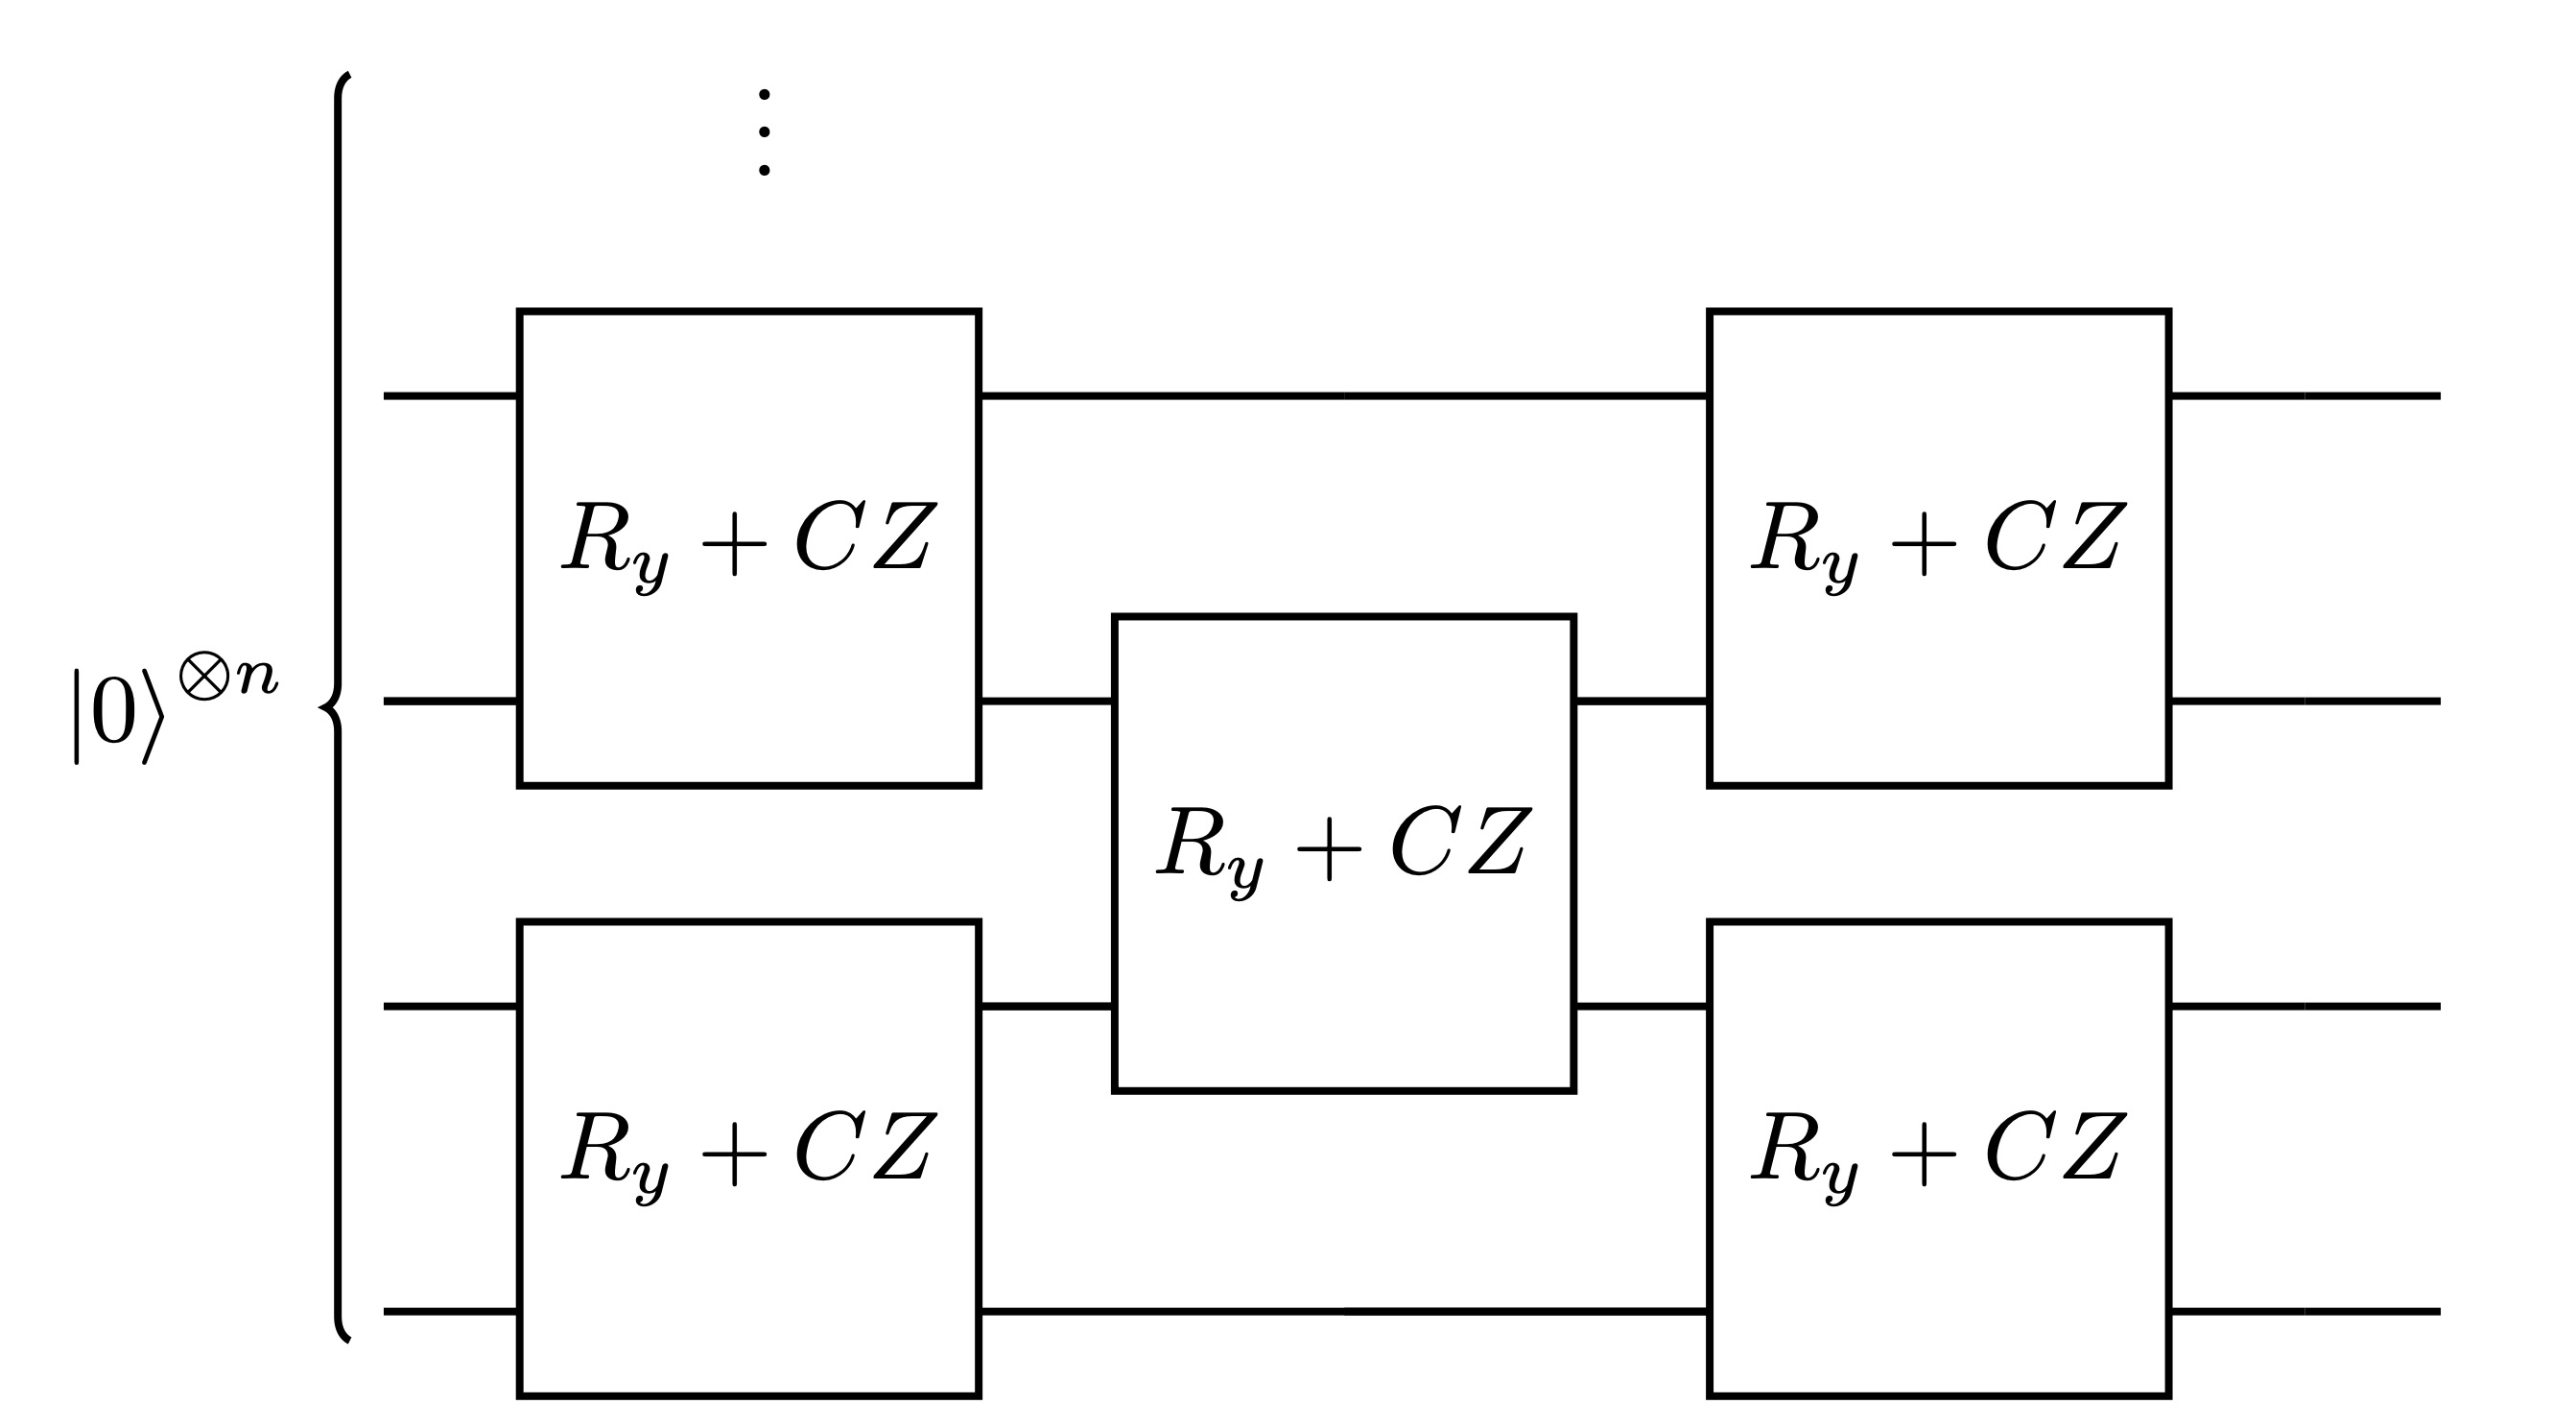

In [4]:
@tf.function
def get_state(v):
    layers = len(v)
    c = tc.Circuit(N)
    # Ry+Cz
    for layer in range(layers):
        if layer % 2 == 0:
            for i in range(0, N, 2):
                c.ry(i, theta=v[layer, i])
                c.ry(i + 1, theta=v[layer, i + 1])
                c.cz(i, i + 1)
        else:
            for i in range(1, N, 2):
                c.ry(i, theta=v[layer, i])
                c.ry((i + 1) % N, theta=v[layer, (i + 1) % N])
                c.cz(i, (i + 1) % N)
    ψ = c.wavefunction()  # the output state
    return ψ

### Hamiltonian

In [5]:
def get_hamiltonian():
    h = []
    w = []
    ###ZZ
    for i in range(N):
        h.append([])
        w.append(1.0)  # weight
        for j in range(N):
            if j == (i + 1) % N or j == i:
                h[i].append(3)
            else:
                h[i].append(0)
    ###potential
    for i in range(N):
        h.append([])
        w.append(1.0)
        for j in range(N):
            if j == i:
                h[i + N].append(1)
            else:
                h[i + N].append(0)

    hamiltonian = tc.quantum.PauliStringSum2Dense(
        tf.constant(h, dtype=tf.complex128), tf.constant(w, dtype=tf.complex128)
    )
    return hamiltonian

### Loss Function

$$
C(\theta) = \langle H \rangle.
$$

In [6]:
@tf.function
def energy_loss(v, hamiltonian):
    ψ = get_state(v)
    ψ = tf.reshape(ψ, [2**N, 1])
    loss = tf.transpose(ψ, conjugate=True) @ hamiltonian @ ψ
    loss = tc.backend.real(loss)
    return loss

### Rényi Entanglement Entropy

$$
R_{A}^{2} = - \rm{log} (\rm{tr}_{A}\rho_{A}^{2}),
$$
where $\rho_{A}$ is the reduced density matrix of one half of the chain, obtained by tracing out the other half.

In [7]:
@tf.function
def entropy(v):
    ψ = get_state(v)
    ρ_reduced = tc.quantum.reduced_density_matrix(
        ψ, NA
    )  # reduced density matrix obtained through partially tracing out subsystem A
    S = tc.quantum.renyi_entropy(ρ_reduced)  # renyi entanglement entropy
    return S

### Main Optimization Loop

In [8]:
def opt_main(v, maxiter=100):
    opt = tc.backend.optimizer(tf.keras.optimizers.Adam(1e-2))

    hamiltonian = get_hamiltonian()

    loss_and_grad_vag = tc.backend.jit(
        tc.backend.vvag(energy_loss, argnums=0, vectorized_argnums=0)
    )  # use vvag to get losses and gradients of different random circuit instances
    entropy_vag = tc.backend.jit(
        tc.backend.vmap(entropy, vectorized_argnums=0)
    )  # use vmap to get renyi entanglement entropy of different random circuit instances

    for i in range(maxiter):
        loss, gr = loss_and_grad_vag(v, hamiltonian)

        if i == 0:
            E_initial_avg = tf.reduce_mean(loss)  # energy of the initial state
            S_initial = entropy_vag(v)
            S_initial_avg = tf.reduce_mean(
                S_initial
            )  # renyi entanglement entropy of the initial state

        v = opt.update(gr, v)

    loss, _ = loss_and_grad_vag(v, hamiltonian)
    E_final_avg = tf.reduce_mean(loss)
    S_final_avg = tf.reduce_mean(entropy_vag(v))

    return (
        E_initial_avg.numpy(),
        E_final_avg.numpy(),
        S_initial_avg.numpy(),
        S_final_avg.numpy(),
    )

In [9]:
v = tf.random.uniform([num_trial, L, N], minval=0.0, maxval=2 * np.pi, dtype=tf.float64)
E_initial, E_final, S_initial, S_final = opt_main(v)

In [10]:
print("Number of layers = ", L, ";")
print(
    "ΔE (initial) = ",
    E_initial - E0,
    ";",
    "ΔE (final) = ",
    E_final - E0,
)
print(
    "S (initial) = ",
    S_initial,
    ";",
    "S (final) = ",
    S_final,
)

Number of layers =  2 ;
ΔE (initial) =  4.302597211771994 ; ΔE (final) =  1.8345094697018456
S (initial) =  0.5038228445598862 ; S (final) =  0.06529184412923318


### Results

The depth sweep below uses 12 qubits and 13 random initializations at each depth, from 8 to 64 layers in steps of 8. Each instance undergoes 1000 parameter updates. Compare the average energy error and second Rényi entropy before and after optimization.

In [11]:
N = 12
NA = list(range(N // 2))
num_trial = 13
layer_counts = list(range(8, 65, 8))

basis = quspin.basis.spin_basis_1d(N)
J_zz = [[1.0, i, (i + 1) % N] for i in range(N)]
J_x = [[1.0, i] for i in range(N)]
H_TFIM = quspin.operators.hamiltonian(
    [["zz", J_zz], ["x", J_x]], [], basis=basis, check_symm=False, dtype=np.float64
)
E, V = H_TFIM.eigsh(k=2, which="SA")
E0 = E[0]
psi0_matrix = V[:, 0].reshape(2 ** (N // 2), -1)
rho0 = psi0_matrix @ psi0_matrix.conj().T
S0 = -np.log(np.trace(rho0 @ rho0).real)
print("The ground state energy:", E0)
print("The spectral gap:", E[1] - E0)
print("The ground state second Rényi entropy:", S0)

results = []
for L in layer_counts:
    v = tf.random.uniform(
        [num_trial, L, N], minval=0.0, maxval=2 * np.pi, dtype=tf.float64
    )
    result = opt_main(v, maxiter=1000)
    results.append(result)
    print(
        f"L={L}: ΔE {result[0] - E0:.8g} -> {result[1] - E0:.8g}, "
        f"Rényi entropy {result[2]:.8g} -> {result[3]:.8g}"
    )
results = np.asarray(results)

Hermiticity check passed!
The ground state energy: -15.322595151080753
The spectral gap: 0.13108692563048407
The ground state second Rényi entropy: 0.5357123329092505


L=8: ΔE 15.631719 -> 0.14142654, Rényi entropy 1.4994537 -> 0.027516575


L=16: ΔE 15.319152 -> 0.083852004, Rényi entropy 2.8036922 -> 0.04426749


L=24: ΔE 15.309934 -> 0.076359532, Rényi entropy 3.2831102 -> 0.047775734


L=32: ΔE 15.366688 -> 0.070777471, Rényi entropy 3.4141482 -> 0.055181641


L=40: ΔE 15.380416 -> 0.072267409, Rényi entropy 3.4491283 -> 0.055368513


L=48: ΔE 15.339108 -> 1.3188922, Rényi entropy 3.4602215 -> 0.35416329


L=56: ΔE 15.355263 -> 7.6812497, Rényi entropy 3.4637919 -> 2.0116028


L=64: ΔE 15.357032 -> 6.8774751, Rényi entropy 3.4621255 -> 1.7639466


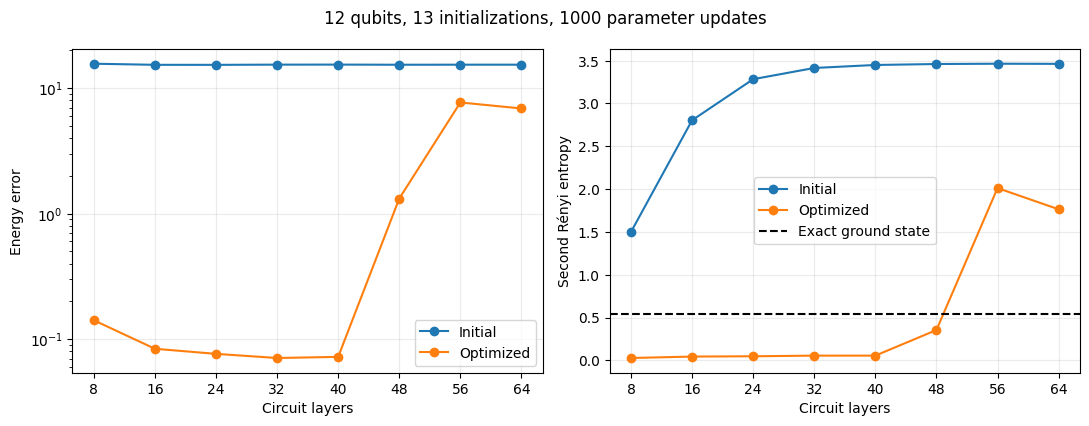

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for column, label, color in [
    (0, "Initial", "tab:blue"),
    (1, "Optimized", "tab:orange"),
]:
    axes[0].semilogy(
        layer_counts, results[:, column] - E0, "o-", label=label, color=color
    )
    axes[1].plot(layer_counts, results[:, column + 2], "o-", label=label, color=color)
axes[1].axhline(S0, color="black", linestyle="--", label="Exact ground state")
axes[0].set_ylabel("Energy error")
axes[1].set_ylabel("Second Rényi entropy")
for ax in axes:
    ax.set(xlabel="Circuit layers", xticks=layer_counts)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("12 qubits, 13 initializations, 1000 parameter updates")
fig.tight_layout()
plt.show()

In this run, the smallest mean energy error is about 0.0708 at 32 layers, where the optimized mean second Rényi entropy is about 0.0552. The dashed line marks the exact ground-state entropy, about 0.5357. The deeper circuits retain larger energy errors and entropies after optimization.

Each depth is trained independently with Adam at learning rate 0.01 for 1000 parameter updates. The reference paper uses a learning rate of 0.05 and 5000 updates.

### Reference

Reference paper: https://arxiv.org/pdf/2201.01452.pdf.